# EDA, Làm sạch & Tạo Đặc trưng One-Step-Ahead (Tuần 2)

Thực hiện chuẩn hóa Z-score, làm sạch NaN/outlier, trực quan hóa phân phối trước/sau khi làm sạch, ma trận tương quan giữa 7 biến mục tiêu và xây dựng tập đặc trưng `144 -> 7`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.dataset import AGES, TREE_BAND, read_pipeline_config, load_ml_ready_npz, load_stats, normalize_array
from src.clean import clean_carbonglobe_arrays
from src.features import build_one_step_dataset

cfg = read_pipeline_config(ROOT / "configs/pipeline.yaml")
raw_dir = ROOT / cfg["paths"]["raw_dir"]
data = load_ml_ready_npz(raw_dir / cfg["paths"]["global_subdir"], cfg["carbonglobe"]["ml_ready_file"])
stats = load_stats(raw_dir / cfg["paths"]["stats_subdir"], cfg["carbonglobe"]["stats_file"])

x_norm = normalize_array(data["x_train"], stats["x_mean"], stats["x_std"], eps=cfg["cleaning"]["eps_std"])
y_norm = normalize_array(data["y_train"], stats["y_mean"], stats["y_std"], eps=cfg["cleaning"]["eps_std"])
x_clean, y_clean, clean_stats = clean_carbonglobe_arrays(x_norm, y_norm, tuple(cfg["cleaning"]["clip_z_range"]))
print("Thống kê làm sạch:", clean_stats)

Thống kê làm sạch: {'x_non_finite_fixed': 14400, 'y_non_finite_fixed': 0, 'x_outliers_clipped': 0, 'y_outliers_clipped': 1}


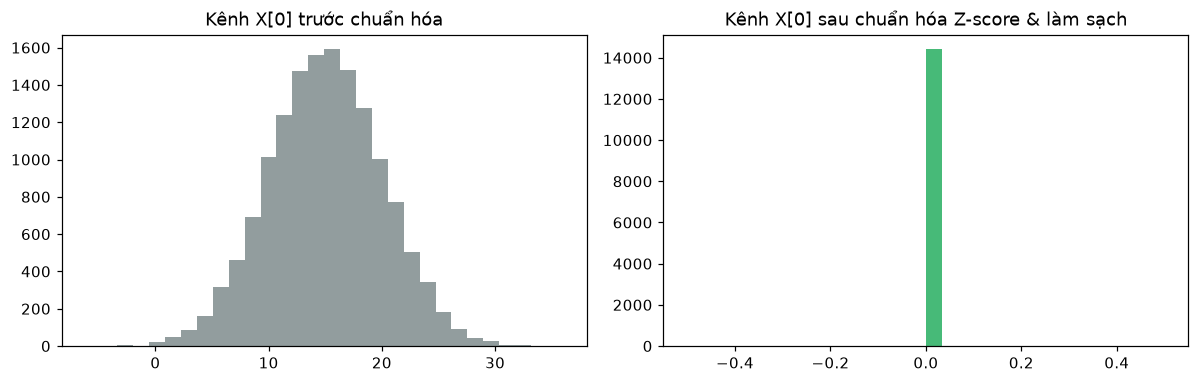

In [2]:
# So sánh phân phối trước và sau chuẩn hóa + làm sạch cho kênh đặc trưng 0 và mục tiêu agb
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
raw_sample = data["x_train"][..., 0].ravel()
raw_sample = raw_sample[np.isfinite(raw_sample)]
axes[0].hist(raw_sample, bins=30, color="#7f8c8d", alpha=0.85)
axes[0].set_title("Kênh X[0] trước chuẩn hóa")

axes[1].hist(x_clean[..., 0].ravel(), bins=30, color="#27ae60", alpha=0.85)
axes[1].set_title("Kênh X[0] sau chuẩn hóa Z-score & làm sạch")
plt.tight_layout()
plt.show()

X_feat shape: (18000, 144) | Y_target shape: (18000, 7)


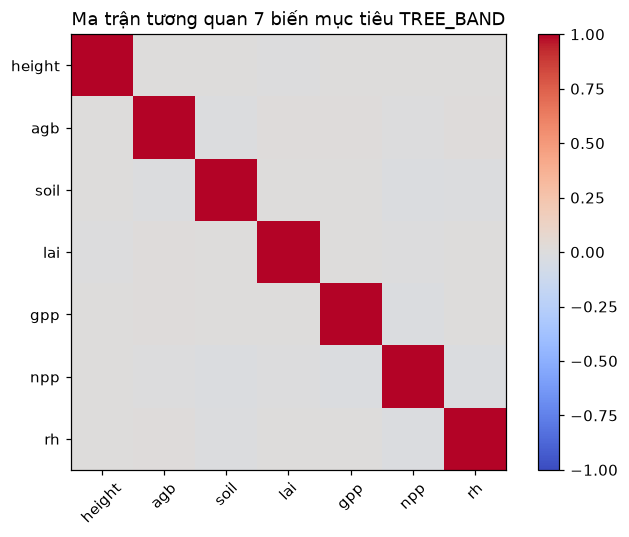

In [3]:
# Xây dựng tập đặc trưng one-step-ahead (144 -> 7) và phân tích tương quan 7 biến mục tiêu
X_feat, Y_target = build_one_step_dataset(x_clean, y_clean, ages=AGES)
print(f"X_feat shape: {X_feat.shape} | Y_target shape: {Y_target.shape}")

corr = pd.DataFrame(Y_target, columns=TREE_BAND).corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(TREE_BAND))); ax.set_xticklabels(TREE_BAND, rotation=45)
ax.set_yticks(range(len(TREE_BAND))); ax.set_yticklabels(TREE_BAND)
ax.set_title("Ma trận tương quan 7 biến mục tiêu TREE_BAND")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()